# Variance Reduction for Asian Options

This notebook prices a fixed-strike arithmetic-average Asian call with Monte Carlo simulation. Because the corresponding geometric-average Asian call has a closed-form price and is highly correlated with the arithmetic-average payoff, it is used as a **control variate** to reduce estimation variance.

The workflow is:

1. Compute the analytical price of the geometric-average Asian call.
2. Simulate geometric Brownian motion paths.
3. Calculate arithmetic and geometric Asian call payoffs on the same paths.
4. Estimate the optimal control-variate coefficient.
5. Compare the standard and variance-reduced estimators.


## 1. Model parameters

We assume that the underlying asset follows geometric Brownian motion under the risk-neutral measure. The parameters below are the initial asset price $S_0$, risk-free rate $r$, volatility $\sigma$, maturity $T$, and strike $K$.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

S0 = 100
r = 0.05
sigma = 0.20
T = 1
K = 100


## 2. Analytical geometric-average Asian call price

For continuous monitoring, the geometric average is lognormally distributed. Its effective volatility and cost-of-carry adjustment are

$$
\sigma_G = \frac{\sigma}{\sqrt{3}},
\qquad
b_G = \frac{1}{2}\left(r-\frac{\sigma_G^2}{2}\right).
$$

These adjusted parameters allow the geometric-average call to be valued with a Black–Scholes-style formula.


In [2]:
geometric_sigma = sigma / np.sqrt(3)
geometric_carry = 0.5 * (r - 0.5 * geometric_sigma**2)

print(f"Effective geometric volatility: {geometric_sigma:.4f}")
print(f"Effective geometric carry: {geometric_carry:.4f}")


Effective geometric volatility: 0.1155
Effective geometric carry: 0.0217


In [3]:
d1 = (
    np.log(S0 / K)
    + (geometric_carry + 0.5 * geometric_sigma**2) * T
) / (geometric_sigma * np.sqrt(T))
d2 = d1 - geometric_sigma * np.sqrt(T)

geometric_call_price = (
    S0 * np.exp((geometric_carry - r) * T) * stats.norm.cdf(d1)
    - K * np.exp(-r * T) * stats.norm.cdf(d2)
)

print(f"d1: {d1}")
print(f"d2: {d2}")
print(f"Analytical geometric Asian call price: {geometric_call_price}")


d1: 0.24537386440559095
d2: 0.12990381056766578
Analytical geometric Asian call price: 5.546818633789201


The value above is the known expected discounted payoff of the geometric-average call. It will serve as the control variate's known mean; the simulated geometric payoff average must not be substituted for it.


## 3. Monte Carlo path simulation

The function below generates $M$ paths with $n$ equally spaced time steps using the exact discretization of geometric Brownian motion:

$$
S_{t+\Delta t}=S_t\exp\left[\left(r-\frac{1}{2}\sigma^2\right)\Delta t+\sigma\sqrt{\Delta t}\,Z\right],
\qquad Z\sim N(0,1).
$$


In [4]:
def create_paths(S0, r, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    paths = np.zeros((n_steps + 1, n_paths))
    paths[0] = S0

    for step in range(n_steps):
        z = np.random.normal(0, 1, n_paths)
        paths[step + 1] = paths[step] * np.exp(
            (r - 0.5 * sigma**2) * dt
            + sigma * np.sqrt(dt) * z
        )

    return paths


### Asian option payoff functions

The arithmetic and geometric averages exclude the initial price and use the same simulated monitoring dates. Both payoff functions return the discounted Monte Carlo estimate of a fixed-strike call.


In [5]:
def arithmetic_asian_call_price(paths, strike, r, T):
    arithmetic_average = np.mean(paths[1:], axis=0)
    discounted_payoffs = np.maximum(arithmetic_average - strike, 0) * np.exp(-r * T)
    return np.mean(discounted_payoffs)


def geometric_asian_call_price(paths, strike, r, T):
    geometric_average = stats.gmean(paths[1:], axis=0)
    discounted_payoffs = np.maximum(geometric_average - strike, 0) * np.exp(-r * T)
    return np.mean(discounted_payoffs)


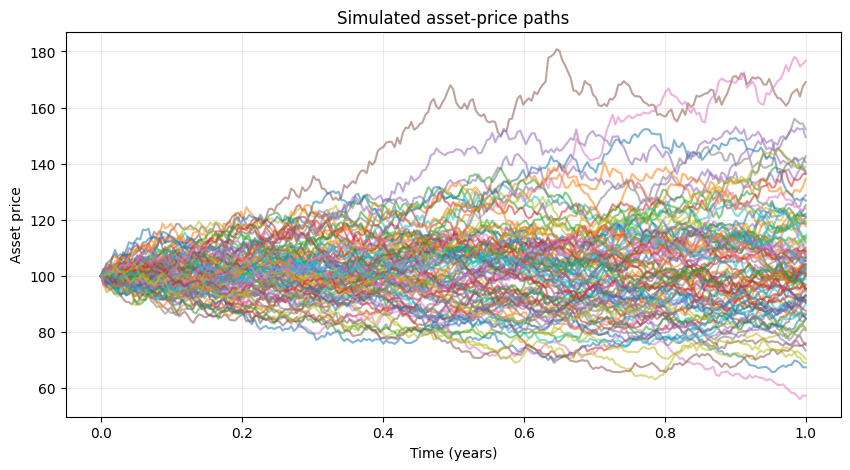

In [6]:
n_steps = 252
n_paths = 100
paths = create_paths(S0, r, sigma, T, n_steps, n_paths)

plt.figure(figsize=(10, 5))
plt.plot(np.linspace(0, T, n_steps + 1), paths, alpha=0.55)
plt.title("Simulated asset-price paths")
plt.xlabel("Time (years)")
plt.ylabel("Asset price")
plt.grid(alpha=0.25)
plt.show()


In [7]:
arithmetic_mc_price = arithmetic_asian_call_price(paths, K, r, T)
geometric_mc_price = geometric_asian_call_price(paths, K, r, T)

print(f"Arithmetic-average Asian call (Monte Carlo): {arithmetic_mc_price}")
print(f"Geometric-average Asian call (Monte Carlo): {geometric_mc_price}")
print(f"Geometric-average Asian call (analytical): {geometric_call_price}")


Arithmetic-average Asian call (Monte Carlo): 5.763196610304715
Geometric-average Asian call (Monte Carlo): 5.554233271408175
Geometric-average Asian call (analytical): 5.546818633789201


## 4. Control-variate estimator

Let $Y$ be the discounted arithmetic-average payoff and $X$ the discounted geometric-average payoff. Since $\mathbb{E}[X]$ is known analytically, the adjusted payoff is

$$
Y_{CV}=Y-\beta\left(X-\mathbb{E}[X]\right),
$$

where the variance-minimizing coefficient is estimated from the same simulation:

$$
\hat\beta=\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}.
$$


In [8]:
arithmetic_average = np.mean(paths[1:], axis=0)
geometric_average = stats.gmean(paths[1:], axis=0)

arithmetic_payoffs = np.maximum(arithmetic_average - K, 0) * np.exp(-r * T)
geometric_payoffs = np.maximum(geometric_average - K, 0) * np.exp(-r * T)

plain_mc_mean = np.mean(arithmetic_payoffs)
known_control_mean = geometric_call_price


In [9]:
covariance_matrix = np.cov(geometric_payoffs, arithmetic_payoffs)
control_variance = covariance_matrix[0, 0]
plain_variance = covariance_matrix[1, 1]
payoff_covariance = covariance_matrix[0, 1]

beta = payoff_covariance / control_variance
correlation = payoff_covariance / np.sqrt(control_variance * plain_variance)

print(f"Estimated control-variate coefficient: {beta}")
print(f"Payoff correlation: {correlation}")


Estimated control-variate coefficient: 1.035785344101251
Payoff correlation: 0.999622293006686


A correlation close to one indicates that the geometric payoff is an effective control variate: both payoffs respond almost identically to the simulated asset paths, while the geometric option's expected value is known.


In [10]:
control_variate_payoffs = arithmetic_payoffs - beta * (
    geometric_payoffs - known_control_mean
)

control_variate_mean = np.mean(control_variate_payoffs)
control_variate_variance = np.var(control_variate_payoffs, ddof=1)


## 5. Results

The table compares the sample variance and expected value of the standard Monte Carlo payoff with those of the control-variate estimator.


In [11]:
results = pd.DataFrame(
    {
        "Variance": [plain_variance, control_variate_variance],
        "Expected value": [plain_mc_mean, control_variate_mean],
    },
    index=["Standard Monte Carlo", "Control-variate Monte Carlo"],
)

results


,Variance,Expected value
Standard Monte Carlo,65.263823,5.763197
Control-variate Monte Carlo,0.049292,5.755517


The percentage reduction in variance is

$$
\text{Variance reduction}
=\left(1-\frac{\operatorname{Var}(Y_{CV})}{\operatorname{Var}(Y)}\right)\times100.
$$


In [12]:
variance_reduction = 100 * (1 - control_variate_variance / plain_variance)
print(f"Variance reduction: {variance_reduction:.2f}%")


Variance reduction: 99.92%


## Conclusion

The control-variate estimator retains the same pricing target as standard Monte Carlo while substantially reducing sampling noise. The improvement comes from combining the arithmetic payoff with the closely related geometric payoff and anchoring the latter to its analytical expected value.
